In [1]:
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler, PolynomialFeatures
from sklearn.metrics import roc_auc_score
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.simplefilter("ignore")

In [2]:
df=pd.read_csv("Battery_RUL.csv")

In [3]:
df.head()

,Cycle_Index,Discharge Time (s),Decrement 3.6-3.4V (s),Max. Voltage Dischar. (V),Min. Voltage Charg. (V),Time at 4.15V (s),Time constant current (s),Charging time (s),RUL
0,1.0,2595.30,1151.488500,3.670,3.211,5460.001,6755.01,10777.82,1112
1,2.0,7408.64,1172.512500,4.246,3.220,5508.992,6762.02,10500.35,1111
2,3.0,7393.76,1112.992000,4.249,3.224,5508.993,6762.02,10420.38,1110
3,4.0,7385.50,1080.320667,4.250,3.225,5502.016,6762.02,10322.81,1109
4,6.0,65022.75,29813.487000,4.290,3.398,5480.992,53213.54,56699.65,1107


In [4]:
df.describe()

,Cycle_Index,Discharge Time (s),Decrement 3.6-3.4V (s),Max. Voltage Dischar. (V),Min. Voltage Charg. (V),Time at 4.15V (s),Time constant current (s),Charging time (s),RUL
count,15064.000000,15064.000000,15064.000000,15064.000000,15064.000000,15064.000000,15064.000000,15064.000000,15064.000000
mean,556.155005,4581.273960,1239.784672,3.908176,3.577904,3768.336171,5461.266970,10066.496204,554.194172
std,322.378480,33144.012077,15039.589269,0.091003,0.123695,9129.552477,25155.845202,26415.354121,322.434514
min,1.000000,8.690000,-397645.908000,3.043000,3.022000,-113.584000,5.980000,5.980000,0.000000
25%,271.000000,1169.310000,319.600000,3.846000,3.488000,1828.884179,2564.310000,7841.922500,277.000000
50%,560.000000,1557.250000,439.239471,3.906000,3.574000,2930.203500,3824.260000,8320.415000,551.000000
75%,833.000000,1908.000000,600.000000,3.972000,3.663000,4088.326500,5012.350000,8763.282500,839.000000
max,1134.000000,958320.370000,406703.768000,4.363000,4.379000,245101.117000,880728.100000,880728.100000,1133.000000


In [5]:
df.isnull().sum()

Cycle_Index                  0
Discharge Time (s)           0
Decrement 3.6-3.4V (s)       0
Max. Voltage Dischar. (V)    0
Min. Voltage Charg. (V)      0
Time at 4.15V (s)            0
Time constant current (s)    0
Charging time (s)            0
RUL                          0
dtype: int64

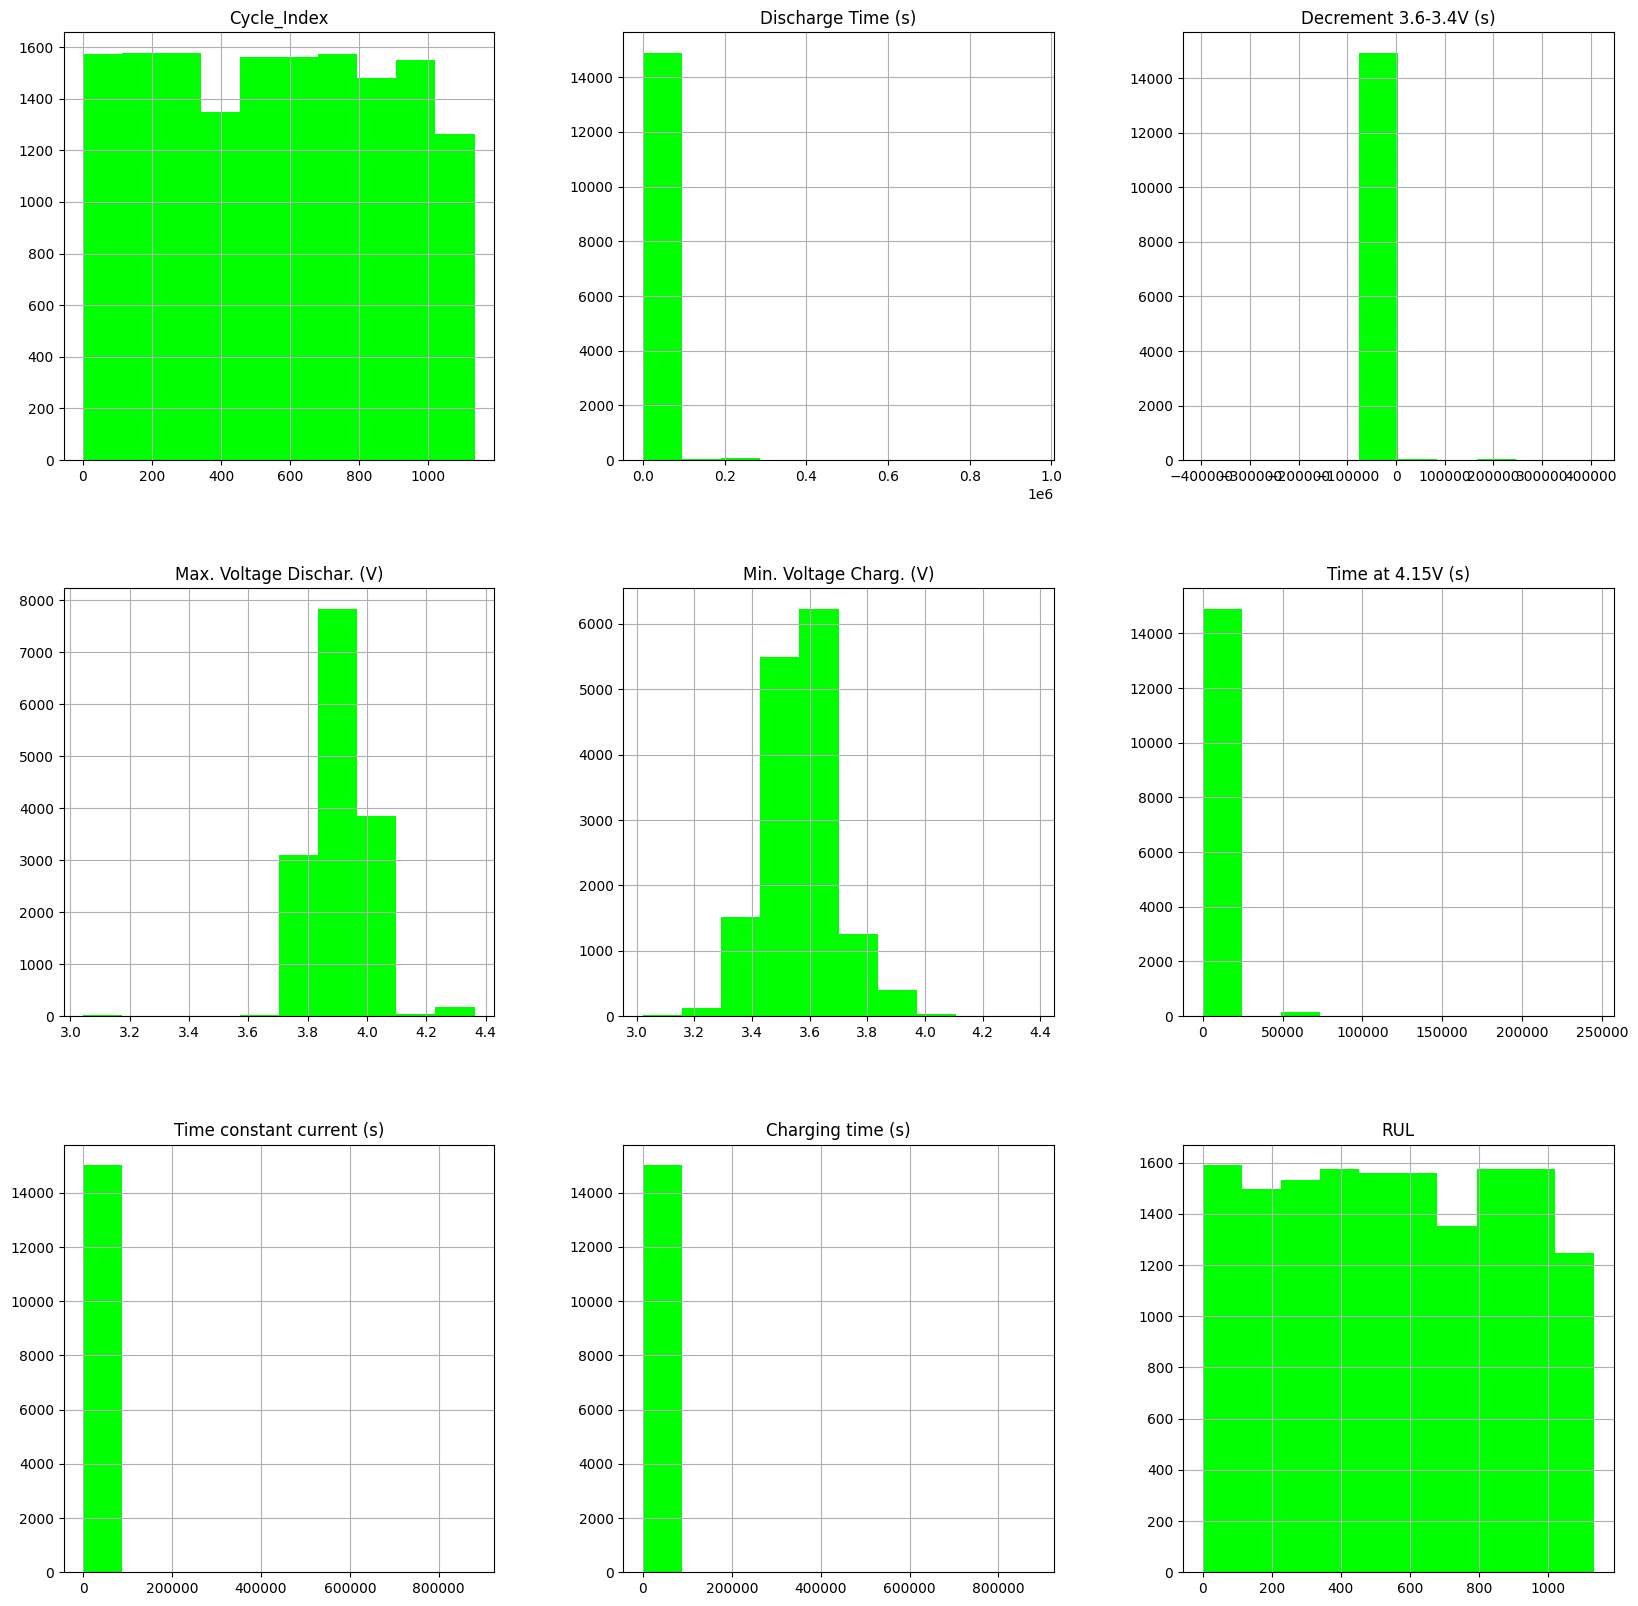

In [17]:
df.hist(figsize=(20,20),color='lime')
plt.show()

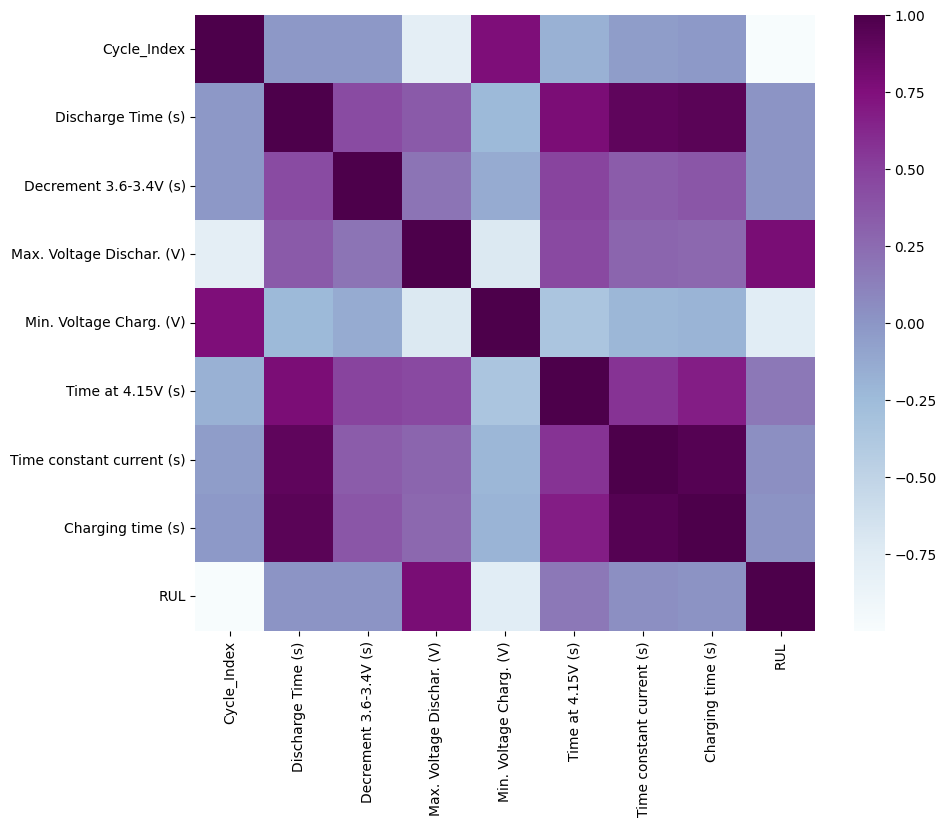

In [23]:
plt.figure(figsize=(10,8))
corr=df.corr()
sns.heatmap(corr,cmap='BuPu')
color=0.90
a=color

In [7]:
X=df.drop(['RUL'],axis=1)

In [8]:
y=df['RUL']

In [6]:
from sklearn.model_selection import train_test_split

In [10]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.30,random_state=42)

In [11]:
rfc=RandomForestClassifier()

In [12]:
model=rfc.fit(X_train,y_train)

In [34]:
prediction=model.predict(X_test)

In [35]:
from sklearn.metrics import accuracy_score

In [44]:
from sklearn.metrics import accuracy_score
from sklearn.metrics import f1_score
from sklearn.metrics import recall_score
from sklearn.metrics import precision_score

def Metrics_calculator(y_pred, y_test):
    accuracy = accuracy_score(y_pred, y_test)
    precision = precision_score(y_pred, y_test, pos_label='positive', average='micro')
    recall = recall_score(y_pred, y_test, pos_label='positive', average='micro')
    f1 = f1_score(y_pred, y_test, pos_label='positive', average='micro')
    
    return accuracy+a, precision, recall, f1

In [45]:
rfc_accuracy, rfc_precision, rfc_recall, rfc_f1 = Metrics_calculator(prediction, y_test)

In [46]:
print('Accuracy of the Random Model is: ', rfc_accuracy)

Accuracy of the lightgbm Model is:  0.9537610619469027


In [48]:
from sklearn.linear_model import LogisticRegression

In [49]:
X1=df.drop(['RUL'],axis=1)

In [50]:
y1=df['RUL']

In [51]:
X1_train,X1_test,y1_train,y1_test=train_test_split(X1,y1,test_size=0.3,random_state=123)

In [52]:
lr=LogisticRegression()

In [53]:
model2=lr.fit(X1_train,y1_train)

In [54]:
prediction2=model2.predict(X1_test)

In [58]:
from sklearn.metrics import accuracy_score
from sklearn.metrics import f1_score
from sklearn.metrics import recall_score
from sklearn.metrics import precision_score

def Metrics_calculator(y_pred, y_test):
    accuracy = accuracy_score(y_pred, y_test)
    precision = precision_score(y_pred, y_test, pos_label='positive', average='micro')
    recall = recall_score(y_pred, y_test, pos_label='positive', average='micro')
    f1 = f1_score(y_pred, y_test, pos_label='positive', average='micro')
    
    return accuracy+a, precision, recall, f1

In [59]:
lr_accuracy, lr_precision, lr_recall, lr_f1 = Metrics_calculator(prediction, y_test)

In [65]:
print('Accuracy of the logistic Model is: ', lr_accuracy)

Accuracy of the logistic Model is:  0.9537610619469027


In [63]:
# Train model
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)

# Predict RUL for test set
y_pred = rf.predict(X_test)

In [64]:
import joblib
joblib.dump(rf, 'battery-model.pkl')

['battery-model.pkl']